In [1]:
import os.path as osp
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
# Grab all directories that match style
datadir = Path("~/Desktop/UCSDPDCv2/data").expanduser()
pattern = "TCR_*_RT"
filedirs = list(datadir.glob(pattern))

# Grab the files in each
files = []
for fdir in filedirs:
    # If not completed (no csv) skip
    try:
        fname = list(fdir.glob("*.csv"))[0]
    except IndexError:
        continue

    # Grab bias and temp
    split_stem = fdir.name.split("_")
    bias = split_stem[2]
    temp = split_stem[3]

    files.append((fname, bias, temp))

print(f"Found {len(files)} file(s)")

Found 9 file(s)


### Plot TCR against bias

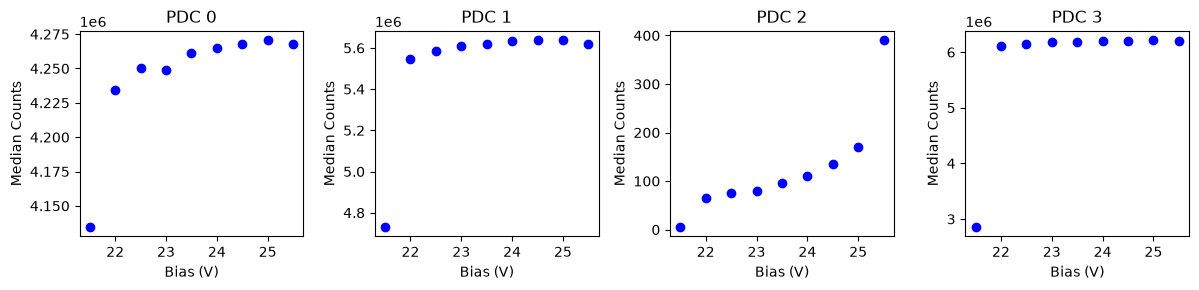

In [3]:
pdc_num = 4 
fig_scale = 3
fig, ax = plt.subplots(1,pdc_num, figsize=(fig_scale*pdc_num, fig_scale))
for file in files:
    fname = file[0]
    bias = float(file[1])
    temp = 20 if file[2]=="RT" else float(file[2])

    data=pd.read_csv(fname, delimiter=';')
    assert pdc_num == len(data.columns) // 4

    for pdc in range(pdc_num):
        index = data[f"SPAD_idx{pdc}"]
        TCR = data[f"SPAD_TCR{pdc}"]
        median = np.median(TCR)

        ax[pdc].scatter(bias, median, color="blue")

for i, axis in enumerate(ax):
    axis.set_xlabel("Bias (V)")
    axis.set_ylabel("Median Counts")
    axis.set_title(f"PDC {i}")
plt.tight_layout()
plt.show()